# Comparative analysis of Forecasting Models

**Models:** Multiple linear regression, Polynomial regression, Ridge, Lasso, Elastic net, Random forest and XGBoost

In [7]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from xgboost import XGBRegressor


In [8]:
DF_PATH = r"..\data\processed\singapore\dataframe.parquet"
TARGET_COL = "system_demand_mw"

HORIZON = "1D"          # how far ahead each row is forecast

N_SPLITS = 4            # cross-validation folds
TEST_DAYS = 182         # length of each fold's test window, in days

TUNE = True             # Toggle hyperparameter tuning on or off
TUNE_SCOPE = "once"     
                        
INNER_SPLITS = 3        # time-series folds inside the tuning search
N_ITER_RF = 8           # random-search candidates for random forest
N_ITER_XGB = 12         # random-search candidates for XGBoost

RANDOM_STATE = 42

In [9]:
feats = pd.read_parquet(DF_PATH).sort_index()

gaps = feats.index.to_series().diff().dropna()
assert gaps.nunique() == 1, "Index is not a regular grid; the lag/rolling shifts below assume one."
step = gaps.iloc[0]
per_day = int(pd.Timedelta("1D") / step)
h_steps = int(pd.Timedelta(HORIZON) / step)
assert h_steps >= 1, "HORIZON must be at least one sampling interval."

print(f"{feats.shape[0]} rows x {feats.shape[1]} columns")
print(f"Horizon = {HORIZON} = {h_steps} steps")

69888 rows x 34 columns
Horizon = 1D = 48 steps


In [10]:
def duration_of(col):
    # "lag_1D" -> 1 day
    return pd.Timedelta(col.split("_")[-1])

lag_all  = [c for c in feats.columns if c.startswith("lag_")]
roll_cols = [c for c in feats.columns if c.startswith("roll_")]

lag_keep = [c for c in lag_all if duration_of(c) >= pd.Timedelta(HORIZON)]
lag_drop = [c for c in lag_all if c not in lag_keep]

hs = feats.copy()
if h_steps > 1:
    hs[roll_cols] = hs[roll_cols].shift(h_steps - 1)

## Separating features for different model families

- For linear models, we use the cyclical features (sin/cos) and one-hot encoded day and hour features
- Tree based models will use the raw datetime features like hours, time_of_day, etc.

In [11]:
cal_tree = [c for c in ["time_of_day", "hour", "day_of_week", "is_weekend", "day_of_month",
                        "day_of_year", "week_of_year", "month", "quarter"] if c in hs.columns]
cal_cyc  = [c for c in hs.columns if c.endswith(("_sin", "_cos"))]

tree_cols = cal_tree + lag_keep + roll_cols
lin_num   = cal_cyc + ["is_weekend"] + lag_keep + roll_cols
lin_cat   = ["day_of_week", "hour"]

# core features expanded by the polynomial model
poly_num = ["time_of_day", "is_weekend"] + lag_keep + [c for c in roll_cols if "_mean_" in c]
rest_num = [c for c in lin_num if c not in poly_num]

used = list(dict.fromkeys(tree_cols + lin_num + lin_cat + poly_num))

X = hs[used]
y = hs[TARGET_COL]

# drop rows where any feature or the target is missing
valid = X.notna().all(axis=1) & y.notna()
print(f"Dropping {int((~valid).sum())} rows with missing features/target "+f"({(~valid).mean() * 100:.2f}%)")
X, y = X[valid], y[valid]

print(f"\nTree features ({len(tree_cols)}): {tree_cols}")
print(f"\nLinear numeric ({len(lin_num)}), categorical: {lin_cat}")
print(f"\nPolynomial core ({len(poly_num)}): {poly_num}")

Dropping 383 rows with missing features/target (0.55%)

Tree features (23): ['time_of_day', 'hour', 'day_of_week', 'is_weekend', 'day_of_month', 'day_of_year', 'week_of_year', 'month', 'quarter', 'lag_1D', 'lag_7D', 'roll_mean_3h', 'roll_std_3h', 'roll_max_3h', 'roll_min_3h', 'roll_mean_1D', 'roll_std_1D', 'roll_max_1D', 'roll_min_1D', 'roll_mean_7D', 'roll_std_7D', 'roll_max_7D', 'roll_min_7D']

Linear numeric (21), categorical: ['day_of_week', 'hour']

Polynomial core (7): ['time_of_day', 'is_weekend', 'lag_1D', 'lag_7D', 'roll_mean_3h', 'roll_mean_1D', 'roll_mean_7D']


## Train-Test Split and Cross Validation folds

In [12]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_DAYS * per_day, gap=h_steps)
folds = list(tscv.split(X))

fold_info = pd.DataFrame([{
    "fold": i + 1,
    "train_start": X.index[tr[0]].date(), "train_end": X.index[tr[-1]].date(),
    "train_days": round(len(tr) / per_day),
    "test_start": X.index[te[0]].date(), "test_end": X.index[te[-1]].date(),
    "test_days": round(len(te) / per_day),
} for i, (tr, te) in enumerate(folds)]).set_index("fold")
fold_info

,train_start,train_end,train_days,test_start,test_end,test_days
fold,,,,,,
1,2022-11-14,2024-11-02,719,2024-11-04,2025-05-04,182
2,2022-11-14,2025-05-03,901,2025-05-05,2025-11-02,182
3,2022-11-14,2025-11-01,1083,2025-11-03,2026-05-03,182
4,2022-11-14,2026-05-02,1265,2026-05-04,2026-11-01,182


## Model Pipelines

In [13]:
def select_cols(cols):
    return ColumnTransformer([("keep", "passthrough", cols)], remainder="drop")

def one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def linear_prep():
    return ColumnTransformer([("num", StandardScaler(), lin_num),
                              ("cat", one_hot(), lin_cat)],
                             remainder="drop", sparse_threshold=0)

def poly_prep():
    return ColumnTransformer(
        [("poly", Pipeline([("scale", StandardScaler()),
                            ("poly", PolynomialFeatures(degree=2, include_bias=False))]), poly_num),
         ("num", StandardScaler(), rest_num),
         ("cat", one_hot(), lin_cat)],
        remainder="drop", sparse_threshold=0)

n_trees = 100
n_iter_rf = N_ITER_RF
n_iter_xgb = N_ITER_XGB

# name -> pipeline, search kind ("grid" / "random" / None), search space, n_iter
SPECS = {
    "Multiple Linear Regression": dict(
        pipe=Pipeline([("prep", linear_prep()), ("model", LinearRegression())]),
        kind=None, grid=None),

    "Polynomial Regression": dict(
        pipe=Pipeline([("prep", poly_prep()), ("model", LinearRegression())]),
        kind="grid", grid={"prep__poly__poly__degree": [2, 3]}),

    "Ridge": dict(
        pipe=Pipeline([("prep", linear_prep()), ("model", Ridge(alpha=1.0))]),
        kind="grid", grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000, 2500]}),

    "Lasso": dict(
        pipe=Pipeline([("prep", linear_prep()), ("model", Lasso(alpha=1.0, max_iter=7500))]),
        kind="grid", grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 500]}),

    "Elastic Net": dict(
        pipe=Pipeline([("prep", linear_prep()), ("model", ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=7500))]),
        kind="grid", grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
                           "model__l1_ratio": [0.2, 0.4,  0.6, 0.8]}),

    "Random Forest": dict(
        pipe=Pipeline([("prep", select_cols(tree_cols)),
                       ("model", RandomForestRegressor(n_estimators=n_trees, min_samples_leaf=5,
                                                       max_features=0.5, n_jobs=-1,
                                                       random_state=RANDOM_STATE))]),
        kind="random", n_iter=n_iter_rf,
        grid={"model__max_depth": [6, 12, 20, None],
              "model__min_samples_leaf": [1, 5, 10, 20],
              "model__max_features": [0.3, 0.5, 0.8, 1.0]}),

    "XGBoost": dict(
        pipe=Pipeline([("prep", select_cols(tree_cols)),
                       ("model", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                                              subsample=0.85, colsample_bytree=0.8,
                                              tree_method="hist", n_jobs=-1,
                                              random_state=RANDOM_STATE))]),
        kind="random", n_iter=n_iter_xgb,
        grid={"model__max_depth": [3, 5, 7, 9],
              "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
              "model__n_estimators": [200, 400, 600, 800],
              "model__subsample": [0.5, 0.7, 0.85, 1.0],
              "model__colsample_bytree": [0.5, 0.7, 0.9, 1.0],
              "model__min_child_weight": [1, 5, 10, 15]}),
}

def build(name):
    return clone(SPECS[name]["pipe"])

## Hyperparameter Tuning and Training

In [14]:
def make_search(name):
    spec = SPECS[name]
    cv = TimeSeriesSplit(n_splits=INNER_SPLITS, gap=h_steps)
    common = dict(cv=cv, scoring="neg_mean_absolute_error", n_jobs=1, refit=True)
    if spec["kind"] == "grid":
        return GridSearchCV(build(name), spec["grid"], **common)
    return RandomizedSearchCV(build(name), spec["grid"], n_iter=spec["n_iter"],
                              random_state=RANDOM_STATE, **common)

tuned_params = {}

def fit_model(name, Xtr, ytr):

    spec = SPECS[name]
    t0 = time.perf_counter()
    if not TUNE or spec["kind"] is None:
        est, params = build(name).fit(Xtr, ytr), None
    elif TUNE_SCOPE == "once" and name in tuned_params:
        params = tuned_params[name]
        est = build(name).set_params(**params).fit(Xtr, ytr)
    else:
        search = make_search(name).fit(Xtr, ytr)
        est, params = search.best_estimator_, search.best_params_
        tuned_params[name] = params
    return est, params, time.perf_counter() - t0

### Evaluation Metrics

In [15]:
def metrics(actual, pred):
    err = np.asarray(pred) - np.asarray(actual)
    return {"MAE": np.abs(err).mean(),
            "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE": (np.abs(err) / np.asarray(actual)).mean() * 100}

In [16]:
rows, oof, tuning_log = [], {}, []

for f, (tr, te) in enumerate(folds, start=1):
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    test_label = f"{X.index[te[0]].date()} to {X.index[te[-1]].date()}"

    # Baseline
    for lag in lag_keep:
        name = f"Naive ({lag})"
        pred = Xte[lag].values
        oof.setdefault(name, []).append(pd.Series(pred, index=yte.index))
        rows.append({"model": name, "fold": f, "test_period": test_label,
                     "train_s": 0.0, **metrics(yte, pred)})

    for name in SPECS:
        est, params, secs = fit_model(name, Xtr, ytr)
        pred = est.predict(Xte)
        oof.setdefault(name, []).append(pd.Series(pred, index=yte.index))
        rows.append({"model": name, "fold": f, "test_period": test_label,
                     "train_s": secs, **metrics(yte, pred)})
        if params is not None:
            tuning_log.append({"model": name, "fold": f,
                               "params": {k.split("__")[-1]: v for k, v in params.items()}})
        print(f"  fold {f}: {name} done")
    print(f"fold {f}/{len(folds)} done ({test_label})")

results = pd.DataFrame(rows)
oof = {k: pd.concat(v) for k, v in oof.items()}
oof_actual = y.loc[oof[next(iter(oof))].index]

  fold 1: Multiple Linear Regression done
  fold 1: Polynomial Regression done
  fold 1: Ridge done


c:\Actually Important Stuff\Work\test\PythonTest\EnergyOracle\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.137159e+06, tolerance: 3.580e+05
  model = cd_fast.enet_coordinate_descent(
c:\Actually Important Stuff\Work\test\PythonTest\EnergyOracle\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.712305e+06, tolerance: 7.113e+05
  model = cd_fast.enet_coordinate_descent(
c:\Actually Important Stuff\Work\test\PythonTest\EnergyOracle\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to inc

  fold 1: Lasso done
  fold 1: Elastic Net done
  fold 1: Random Forest done
  fold 1: XGBoost done
fold 1/4 done (2024-11-04 to 2025-05-04)
  fold 2: Multiple Linear Regression done
  fold 2: Polynomial Regression done
  fold 2: Ridge done
  fold 2: Lasso done
  fold 2: Elastic Net done
  fold 2: Random Forest done
  fold 2: XGBoost done
fold 2/4 done (2025-05-05 to 2025-11-02)
  fold 3: Multiple Linear Regression done
  fold 3: Polynomial Regression done
  fold 3: Ridge done
  fold 3: Lasso done
  fold 3: Elastic Net done
  fold 3: Random Forest done
  fold 3: XGBoost done
fold 3/4 done (2025-11-03 to 2026-05-03)
  fold 4: Multiple Linear Regression done
  fold 4: Polynomial Regression done
  fold 4: Ridge done
  fold 4: Lasso done
  fold 4: Elastic Net done
  fold 4: Random Forest done
  fold 4: XGBoost done
fold 4/4 done (2026-05-04 to 2026-11-01)


# Results

In [17]:
summary = results.groupby("model")[["MAE", "RMSE", "MAPE", "train_s"]].agg(["mean", "std"])
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.sort_values("MAE_mean")
summary.insert(0, "rank", range(1, len(summary) + 1))
summary.round(2)

,rank,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_std,train_s_mean,train_s_std
model,,,,,,,,,
Polynomial Regression,1,132.14,21.50,178.78,11.98,1.87,0.23,0.44,0.27
Multiple Linear Regression,2,136.14,8.26,181.68,8.49,1.95,0.10,0.11,0.03
Ridge,3,137.91,7.84,183.97,8.24,1.97,0.10,0.19,0.29
Lasso,4,139.68,8.23,191.24,10.28,1.99,0.18,70.59,140.65
Elastic Net,5,141.54,7.43,187.87,7.55,2.02,0.10,37.57,72.31
XGBoost,6,154.55,55.92,211.05,64.68,2.13,0.63,6.52,11.91
Naive (lag_7D),7,170.06,17.33,240.20,21.11,2.44,0.33,0.00,0.00
Random Forest,8,171.65,90.84,245.38,126.74,2.34,1.05,8.15,10.08
Naive (lag_1D),9,209.30,9.73,317.80,6.86,2.94,0.13,0.00,0.00


**Linear models beat tree models.** 
- The linear models cluster at 132–141 MW MAE. Random Forest is the worst model tested and loses even to the lag_7D naive baseline. 
- Both tree models are also very unstable across folds, with a standard deviation of 55-90 MW against 8–21 MW for the linear models. 
- Tree models get worse at predicting beyond the range encountered in training

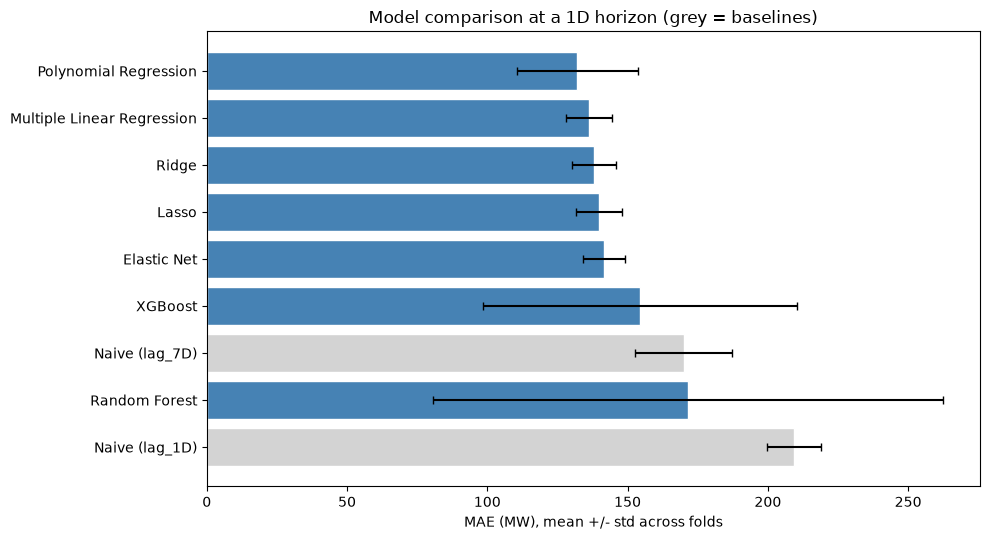

In [24]:
is_naive = lambda m: m.startswith("Naive")

fig, ax = plt.subplots(figsize=(10, 0.5 * len(summary) + 1))
colors = ["lightgrey" if is_naive(m) else "steelblue" for m in summary.index][::-1]
ax.barh(list(summary.index[::-1]), summary["MAE_mean"][::-1], xerr=summary["MAE_std"][::-1],
        color=colors, edgecolor="white", capsize=3)
ax.set_xlabel("MAE (MW), mean +/- std across folds")
ax.set_title(f"Model comparison at a {HORIZON} horizon (grey = baselines)")
fig.tight_layout() 
plt.show()

Although Polynomial Regression shows the best results over all 4 folds, its MAE fluctuates quite heavily from fold to fold with a standard deviation of 21.5 in MAE. Polynomial regression's MAE seems to increase in the second quarter of the year, especially in fold 4 where demand showed the steepest increase.  

On the other hand, Multiple Linear Regression maintains a much lower standard deviation of 8.26 over 4 folds without much change in MAE. It maintains a stable MAE even in the fourth fold.

So the best overall predictor is the linear model - **Multiple Linear Regression**

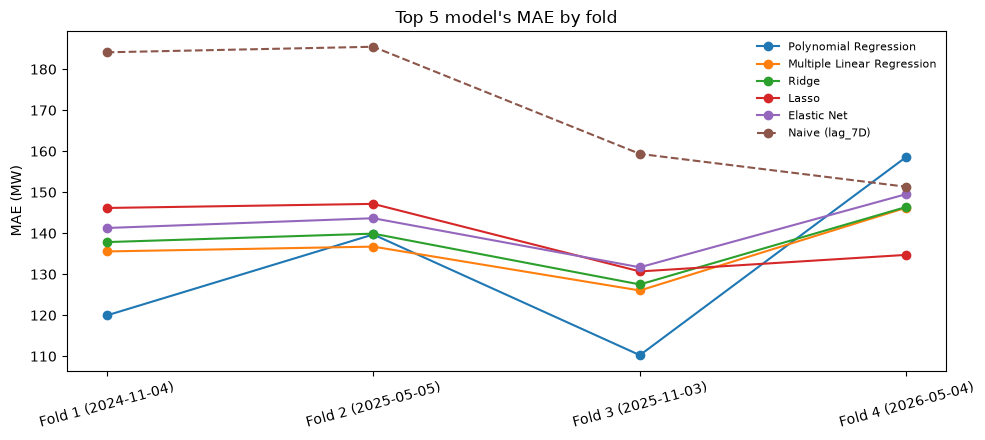

In [27]:
top_models = [m for m in summary.index if not is_naive(m)][:5]
best_naive = next(m for m in summary.index if is_naive(m))
show = top_models + [best_naive]

fig, ax = plt.subplots(figsize=(10, 4.5))
for m in show:
    d = results[results.model == m].sort_values("fold")
    ax.plot(d["fold"], d["MAE"], marker="o", ls="--" if is_naive(m) else "-", label=m)
ax.set_xticks(fold_info.index)
ax.set_xticklabels([f"Fold {i} ({fold_info.loc[i, 'test_start']})" for i in fold_info.index],
                   fontsize=10, rotation=15)
ax.set_ylabel("MAE (MW)"); ax.set_title("Top 5 model's MAE by fold")
ax.legend(fontsize=8, frameon=False) 
fig.tight_layout() 
plt.show()

### Growing under-forecast:

Over the last fold we see a steady increase in demand which is not well predicted even by the best models. Through 2025 the bias hovers between roughly +45 and −100 MW. From early 2026 it drifts steadily negative, reaching about −140 MW for the linear models and about −195 MW for Polynomial by Oct 2026. 

The same period shows MAE rising for Polynomial (to ~195 MW) while Ridge and Multiple Linear Regression hold around 140–150 MW. The likely explanation is that demand level is rising faster than the models, which are fitted on older data, can follow.

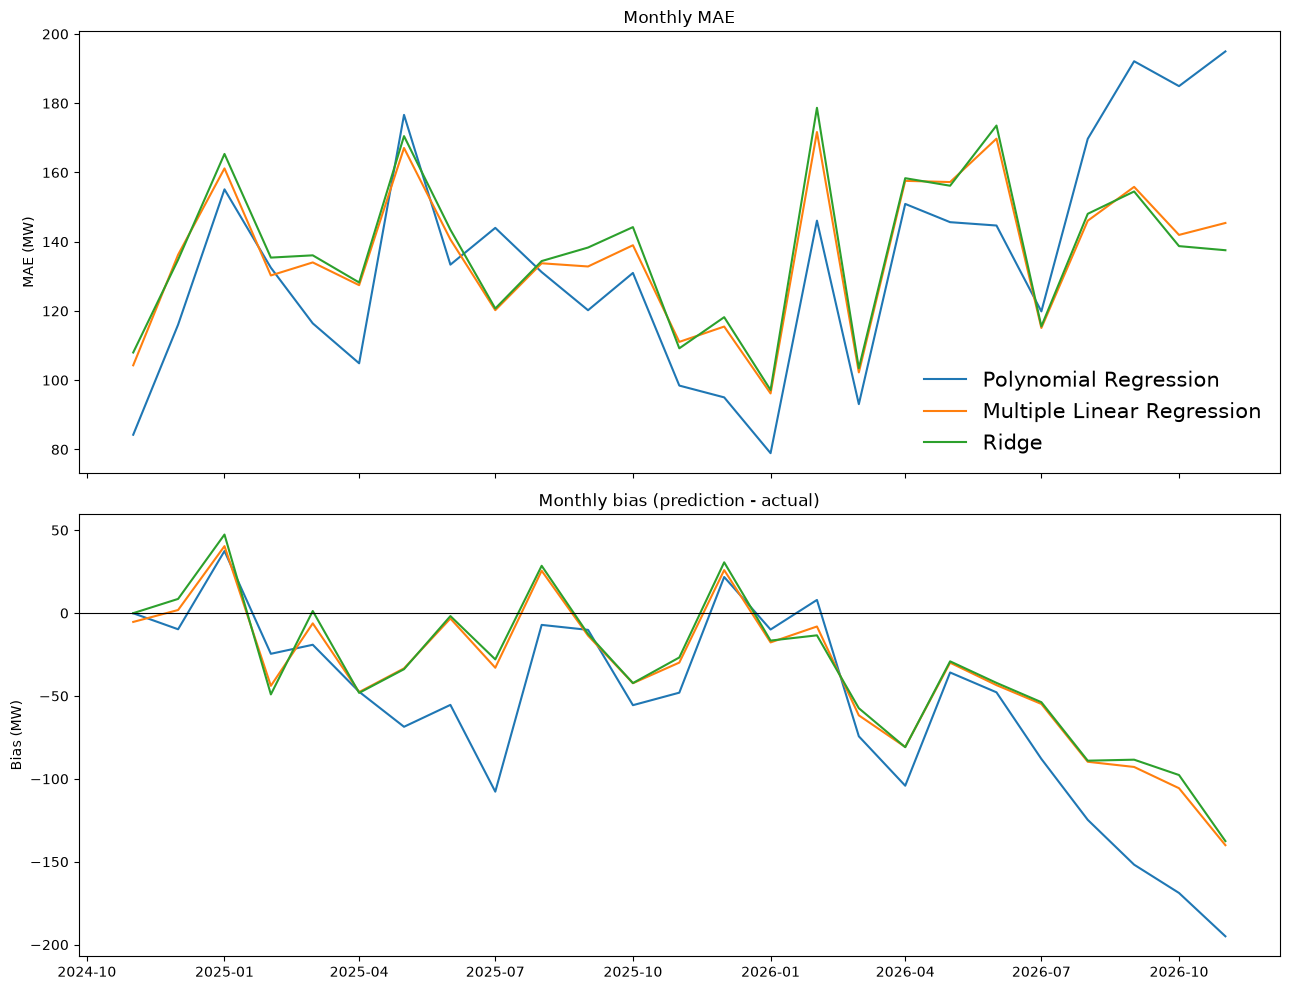

In [ ]:
idx = oof_actual.index
month = (idx.tz_localize(None) if idx.tz is not None else idx).to_period("M")

fig, axs = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for m in top_models[:3]:
    err = oof[m] - oof_actual
    ls = "--" if is_naive(m) else "-"
    axs[0].plot(err.abs().groupby(month).mean().to_timestamp(), ls=ls, label=m)
    axs[1].plot(err.groupby(month).mean().to_timestamp(), ls=ls, label=m)
axs[0].set_ylabel("MAE (MW)"); axs[0].set_title("Monthly MAE")
axs[1].axhline(0, color="k", lw=.8); axs[1].set_ylabel("Bias (MW)")
axs[1].set_title("Monthly bias (prediction - actual)")
axs[0].legend(fontsize=15, frameon=False); fig.tight_layout(); plt.show()